# MNIST: PCA with Logistic Regression

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Explore dimensionality reduction before handwritten digit classification.

**Approach:** PCA feature extraction and logistic regression baseline.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Mini Project  : ACP  </span>
    </span>
    </center>
<br>


### GUERBOUZ MOHAMMED ALAA EDDINE

# MNIST Dataset Analysis with PCA and Logistic Regression

This project involves analyzing the MNIST dataset of handwritten digits using Principal Component Analysis (PCA) and Logistic Regression. We'll walk through each step, from loading the data to evaluating the model's performance.

## Step 1: Import Necessary Packages

We start by importing the necessary Python libraries. These include libraries for data manipulation, visualization, and machine learning.

```python
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, classification_report

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

### Step 2: Load the MNIST Dataset
The MNIST dataset is loaded using fetch_openml from sklearn.datasets. This dataset contains 70,000 images of handwritten digits, each of size 28x28 pixels. The dataset is split into:

Features (X): The pixel values of the images.

Labels (y): The corresponding digit (0 to 9) for each image.

In [15]:
# Load MNIST dataset
mnist = fetch_openml('mnist_784', version=1)
X, y = mnist["data"], mnist["target"]

C:\Users\Dingue\anaconda3\Lib\site-packages\sklearn\datasets\_openml.py:968: FutureWarning: The default value of `parser` will change from `'liac-arff'` to `'auto'` in 1.4. You can set `parser='auto'` to silence this warning. Therefore, an `ImportError` will be raised from 1.4 if the dataset is dense and pandas is not installed. Note that the pandas parser may return different data types. See the Notes Section in fetch_openml's API doc for details.
  warn(


### Step 4: Split the Data into Training and Test Sets
To evaluate the model’s performance on unseen data, we split the dataset into:

Training set (80%): Used to train the model.

Test set (20%): Used to evaluate the model.

This ensures that the model is tested on data it has never seen before, providing a realistic measure of its performance.

In [17]:
# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Step 5: Normalize the Data
Normalization is a crucial preprocessing step. It ensures that all features (pixel values) are on the same scale. We use StandardScaler to standardize the data so that each feature has a mean of 0 and a standard deviation of 1. This helps improve the performance of machine learning algorithms.

In [18]:
# Normalize the data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### Step 6: Apply PCA and Visualize Explained Variance
Principal Component Analysis (PCA) is used to reduce the dimensionality of the data while retaining as much variance as possible. PCA transforms the data into a set of orthogonal components. We plot the cumulative explained variance to decide how many components to keep. This helps us balance between reducing dimensionality and retaining information.

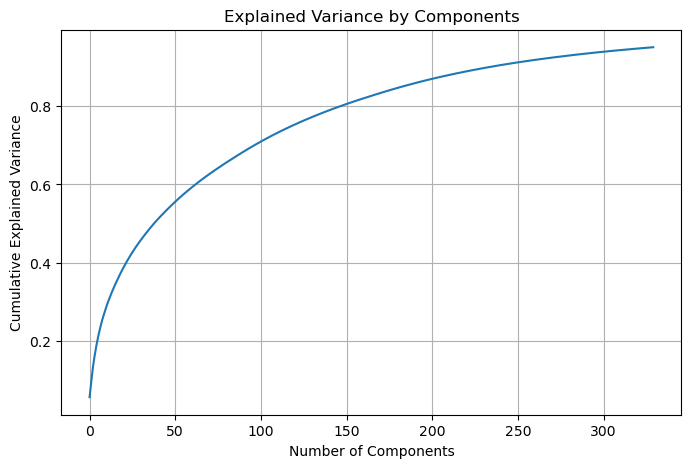

In [19]:
# Apply PCA
pca = PCA(n_components=0.95)  # Retain 95% of the variance
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
# Plot the explained variance ratio
plt.figure(figsize=(8, 5))
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance by Components')
plt.grid(True)
plt.show()

### Step 7: Train a Logistic Regression Model
We use Logistic Regression, a common classification algorithm, to train our model on the PCA-transformed data. Logistic Regression is well-suited for multi-class classification tasks like digit recognition.

In [20]:
# Train a Logistic Regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train_pca, y_train)

LogisticRegression(max_iter=1000)

### Step 8: Make Predictions and Evaluate the Model
After training the model, we make predictions on the test set and evaluate its performance using several metrics:

Accuracy: The percentage of correctly classified samples.

F1 Score: The harmonic mean of precision and recall, useful for imbalanced datasets.

Recall: The percentage of actual positives correctly identified.

Precision: The percentage of predicted positives that are actually correct.

We also generate a classification report, which provides a detailed breakdown of these metrics for each class (digit).

In [21]:
# Make predictions
y_pred = model.predict(X_test_pca)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")

Accuracy: 0.92


In [24]:
# Calculate F1 score, recall, and precision
from sklearn.metrics import f1_score, recall_score, precision_score, classification_report

f1 = f1_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
precision = precision_score(y_test, y_pred, average='weighted')

print(f"F1 Score: {f1:.2f}")
print(f"Recall: {recall:.2f}")
print(f"Precision: {precision:.2f}")

F1 Score: 0.92
Recall: 0.92
Precision: 0.92


### Step 9: Visualize PCA Components
To better understand what PCA is doing, we visualize the first few principal components. These components represent the directions in the data that capture the most variance. By reshaping them back into 28x28 images, we can see what these components look like.

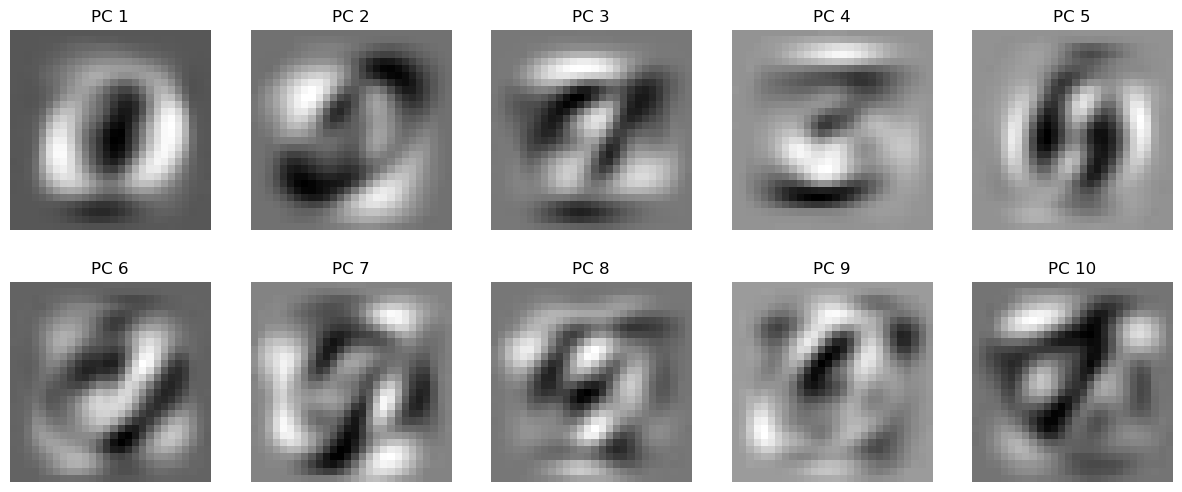

In [22]:
# Visualize the first few principal components
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(pca.components_[i].reshape(28, 28), cmap='gray')
    ax.set_title(f"PC {i+1}")
    ax.axis('off')
plt.show()

### Step 10: Display and Explain Parameters
Finally, we display the number of components used in PCA and the explained variance ratio. This tells us how much variance is retained by the selected components. For example, if we retain 95% of the variance, it means that the reduced dataset still captures most of the information from the original data.

In [25]:
# Display the number of components and explained variance
print(f"Number of components: {pca.n_components_}")
print(f"Explained variance ratio: {pca.explained_variance_ratio_}")

Number of components: 330
Explained variance ratio: [0.05674894 0.04052038 0.03759499 0.02907834 0.02528556 0.02197258
 0.01914912 0.01756493 0.01531724 0.01394287 0.01346865 0.01210102
 0.01120584 0.01099131 0.01031526 0.00997519 0.00937808 0.00922133
 0.00892994 0.00863866 0.00822323 0.0080086  0.00767253 0.00744882
 0.00717186 0.00691635 0.00678958 0.00660055 0.00632077 0.00611889
 0.00601811 0.00590087 0.00567522 0.00559147 0.00554861 0.00537409
 0.00526101 0.00520265 0.0051269  0.00484158 0.00478398 0.00468259
 0.0045823  0.00454495 0.00447476 0.00439989 0.00438052 0.00431537
 0.00425739 0.00418337 0.00411556 0.00402809 0.0039963  0.00395103
 0.00389865 0.00374943 0.00371542 0.00370084 0.00362628 0.00358971
 0.00353225 0.00348861 0.00344175 0.00342785 0.00338368 0.00332069
 0.00328876 0.00323511 0.0031835  0.00316415 0.00312492 0.00310254
 0.00307232 0.00302632 0.0029922  0.00297984 0.00295882 0.00293037
 0.00291351 0.00285588 0.0028378  0.00282164 0.00280412 0.00279498
 0.0027817